# Vidal et al. (2019) Case 2: full-to-full transfer

Case 2 loads a formal Case 1 source checkpoint, transfers only `model_state_dict`, reinitializes the target optimizer/scheduler/scaler, fine-tunes on the target `full_train` split, and evaluates the target `test` split. This notebook defaults to a 2-epoch smoke run for `lg_hg2 -> samsung_30t`; it does not start six 515-epoch formal runs automatically.

Reconstruction assumptions: SOC v2 is a cycler-derived benchmark reference, each record is resampled independently to 1 Hz, `seq_len=50`, `stride=50`, and normalization is fit on target `full_train` only.

In [2]:
!git clone https://github.com/zhangcastle/battery-soc-transfer-benchmark.git /content/battery-soc-transfer-benchmark

Cloning into '/content/battery-soc-transfer-benchmark'...
remote: Enumerating objects: 981, done.
remote: Counting objects: 100% (110/110), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 981 (delta 47), reused 88 (delta 38), pack-reused 871 (from 2)
Receiving objects: 100% (981/981), 268.78 MiB | 18.07 MiB/s, done.
Resolving deltas: 100% (446/446), done.
Updating files: 100% (573/573), done.


In [3]:
%cd /content/battery-soc-transfer-benchmark
!pip install -e .

/content/battery-soc-transfer-benchmark
Obtaining file:///content/battery-soc-transfer-benchmark
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for battery-benchmark (pyproject.toml) ... done
  Created wheel for battery-benchmark: filename=battery_benchmark-0.1.0-0.editable-py3-none-any.whl size=4931 sha256=10db019f592cfd7cbe2b19f97281eff0fc5f8e04aad6463536c4f95baed23a32
  Stored in directory: /tmp/pip-ephem-wheel-cache-23amcodu/wheels/aa/1e/7b/d0aa0266aea215b6e05c2aa27d082e08743b9cc3d136715050
Successfully built battery-benchmark


In [6]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import Image, display

REPO_ROOT = Path('/content/battery-soc-transfer-benchmark')
DRIVE_ROOT = Path('/content/drive/MyDrive/battery_soc_benchmark')
VIDAL_V2_ROOT = DRIVE_ROOT / 'data/labelled/vidal_sequence_v2'
CASE1_OUTPUT_ROOT = DRIVE_ROOT / 'outputs/vidal_case1'
CASE2_OUTPUT_ROOT = DRIVE_ROOT / 'outputs/vidal_case2'
LOCAL_CACHE_ROOT = Path('/content/battery_soc_cache/vidal_case2')

if not REPO_ROOT.is_dir():
    raise FileNotFoundError(
        f'Missing repo: {REPO_ROOT}. Run notebooks/00_colab_setup.ipynb first, '
        'or clone https://github.com/zhangcastle/battery-soc-transfer-benchmark.git to /content.'
    )
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

print("Paths configured:")
print(VIDAL_V2_ROOT)
print(CASE1_OUTPUT_ROOT)
print(CASE2_OUTPUT_ROOT)

Mounted at /content/drive
Paths configured:
/content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2
/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1
/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2


## Git, SOC v2, and Case 1 formal checkpoint preflight

In [7]:
from battery_benchmark.data.vidal_sequence_v2_dataset import validate_case1_roots
commit = subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=REPO_ROOT, text=True).strip()
dirty = bool(subprocess.check_output(['git', 'status', '--porcelain'], cwd=REPO_ROOT, text=True).strip())
print('Commit:', commit, 'dirty:', dirty)
checks = validate_case1_roots(VIDAL_V2_ROOT)
display(checks)
assert (checks.status == 'PASS').all(), 'Required SOC v2 Drive input is missing'

rows = []
for dataset in ['panasonic_18650pf', 'lg_hg2', 'samsung_30t']:
    root = CASE1_OUTPUT_ROOT / dataset / 'seed_42'
    for meta_path in sorted(root.glob('*/run_metadata.json')):
        run = meta_path.parent
        meta = json.loads(meta_path.read_text())
        ckpt = run / 'checkpoints' / 'epoch_515.pt'
        metrics = run / 'metrics.json'
        if meta.get('dataset') == dataset:
            rows.append({
                'dataset': dataset,
                'run_path': str(run),
                'checkpoint': str(ckpt),
                'checkpoint_exists': ckpt.is_file(),
                'metrics_exists': metrics.is_file(),
                'run_mode': meta.get('run_mode'),
                'development_only': meta.get('development_only'),
                'git_commit': meta.get('git_commit'),
            })
case1_runs = pd.DataFrame(rows)
display(case1_runs)
formal = case1_runs[(case1_runs.run_mode == 'formal') & (case1_runs.development_only == False) & case1_runs.checkpoint_exists & case1_runs.metrics_exists]
print('Formal Case 1 checkpoints found:', len(formal))

Commit: db5adbe5c60997299ba45114a27693333a7cfa6c dirty: False


,dataset,split,index,metadata,concatenated,records,status
0,panasonic_18650pf,full_train,True,True,True,True,PASS
1,panasonic_18650pf,partial_train,True,True,True,True,PASS
2,panasonic_18650pf,test,True,True,True,True,PASS
3,lg_hg2,full_train,True,True,True,True,PASS
4,lg_hg2,partial_train,True,True,True,True,PASS
5,lg_hg2,test,True,True,True,True,PASS
6,samsung_30t,full_train,True,True,True,True,PASS
7,samsung_30t,partial_train,True,True,True,True,PASS
8,samsung_30t,test,True,True,True,True,PASS


,dataset,run_path,checkpoint,checkpoint_exists,metrics_exists,run_mode,development_only,git_commit
0,panasonic_18650pf,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,True,True,formal,False,c4728bbaf60430f31640fc0f20958feabefb8c53
1,lg_hg2,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,True,True,formal,False,c4728bbaf60430f31640fc0f20958feabefb8c53
2,samsung_30t,/content/drive/MyDrive/battery_soc_benchmark/o...,/content/drive/MyDrive/battery_soc_benchmark/o...,True,True,formal,False,c4728bbaf60430f31640fc0f20958feabefb8c53


Formal Case 1 checkpoints found: 3


## Smoke pair: LG HG2 -> Samsung 30T

This cell requires a formal LG HG2 Case 1 checkpoint. If the table above is empty for `lg_hg2`, run Case 1 formal first or provide `SOURCE_CHECKPOINT` manually.

In [8]:
SOURCE = 'lg_hg2'
TARGET = 'samsung_30t'
match = formal[formal.dataset == SOURCE]
assert not match.empty, f'Missing formal Case 1 source checkpoint for {SOURCE}'
SOURCE_CHECKPOINT = Path(match.iloc[-1].checkpoint)
print('Using source checkpoint:', SOURCE_CHECKPOINT)

!python {REPO_ROOT}/scripts/run_vidal_case2.py   --source {SOURCE}   --target {TARGET}   --config {REPO_ROOT}/configs/experiments/vidal_case2_smoke.yaml   --input-root {VIDAL_V2_ROOT}   --output-root {CASE2_OUTPUT_ROOT}   --case1-output-root {CASE1_OUTPUT_ROOT}   --source-checkpoint {SOURCE_CHECKPOINT}   --cache-root {LOCAL_CACHE_ROOT}   --run-mode smoke   --device auto   --max-train-windows 32

Using source checkpoint: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/lg_hg2/seed_42/20260716_090927_c4728bba/checkpoints/epoch_515.pt
[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2/_smoke/source_lg_hg2__target_samsung_30t/seed_42/20260716_110011_db5adbe5",
    "metrics": {
      "mae_fraction": 0.09858656797761829,
      "mae_percent": 9.85865679776183,
      "rmse_fraction": 0.11584074230598293,
      "rmse_percent": 11.584074230598294,
      "max_error_fraction": 0.3275696337223053,
      "max_error_percent": 32.75696337223053,
      "bias_fraction": 0.04579484222248027,
      "bias_percent": 4.579484222248027,
      "r2": 0.8829750396124084
    },
    "comparison_to_case1": {
      "baseline_available": true,
      "target_case1_run_path": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/samsung_30t/seed_42/20260716_091258_c4728bba",
      "case1_target_rmse_percent": 2.8078941683251415,
      "case2_rmse_

## Inspect latest smoke result

Latest Case 2 smoke: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2/_smoke/source_lg_hg2__target_samsung_30t/seed_42/20260716_110011_db5adbe5
source checkpoint: /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/lg_hg2/seed_42/20260716_090927_c4728bba/checkpoints/epoch_515.pt
checkpoint sha256: b78d5139bd838283064f7448a8898d4d2bdc58fe6974370ea89c84d153ca1827
initial_target_mse_before_training: 0.0027323956601321697
final_target_train_mse: 0.05640001222491264
metrics: {'mae_fraction': 0.09858656797761829, 'mae_percent': 9.85865679776183, 'rmse_fraction': 0.11584074230598293, 'rmse_percent': 11.584074230598294, 'max_error_fraction': 0.3275696337223053, 'max_error_percent': 32.75696337223053, 'bias_fraction': 0.04579484222248027, 'bias_percent': 4.579484222248027, 'r2': 0.8829750396124084}
comparison: {'baseline_available': True, 'target_case1_run_path': '/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/samsung_30t/seed_42/20260716_091258_c4

,dataset,feature_names,feature_min,feature_max,feature_range,fit_split,n_fit_samples,git_commit,git_dirty,timestamp,normalization_status,sampling_protocol,resample_hz,target_scaler_refit,source_scaler_used
0,samsung_30t,"[voltage, current, temperature]","[2.4990692138671875, -35.9998893737793, 23.870...","[4.202008247375488, 11.99921989440918, 33.4404...","[0.0, 1.0]",full_train,73143,db5adbe5c60997299ba45114a27693333a7cfa6c,False,2026-07-16T11:00:07.857115+00:00,reconstruction_assumption,paper_aligned_1hz_reconstructed,1.0,True,False


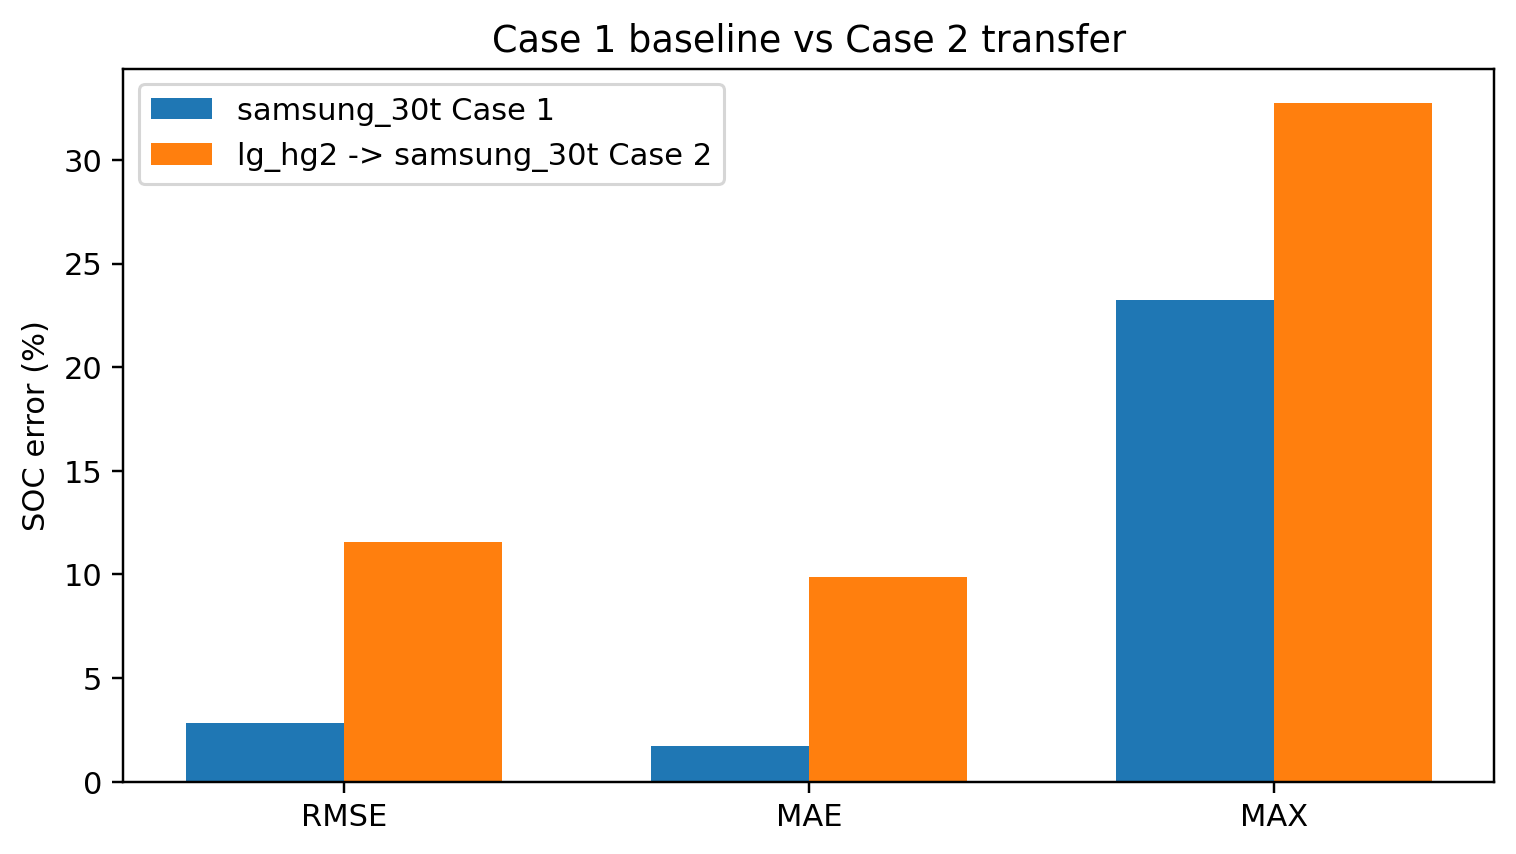

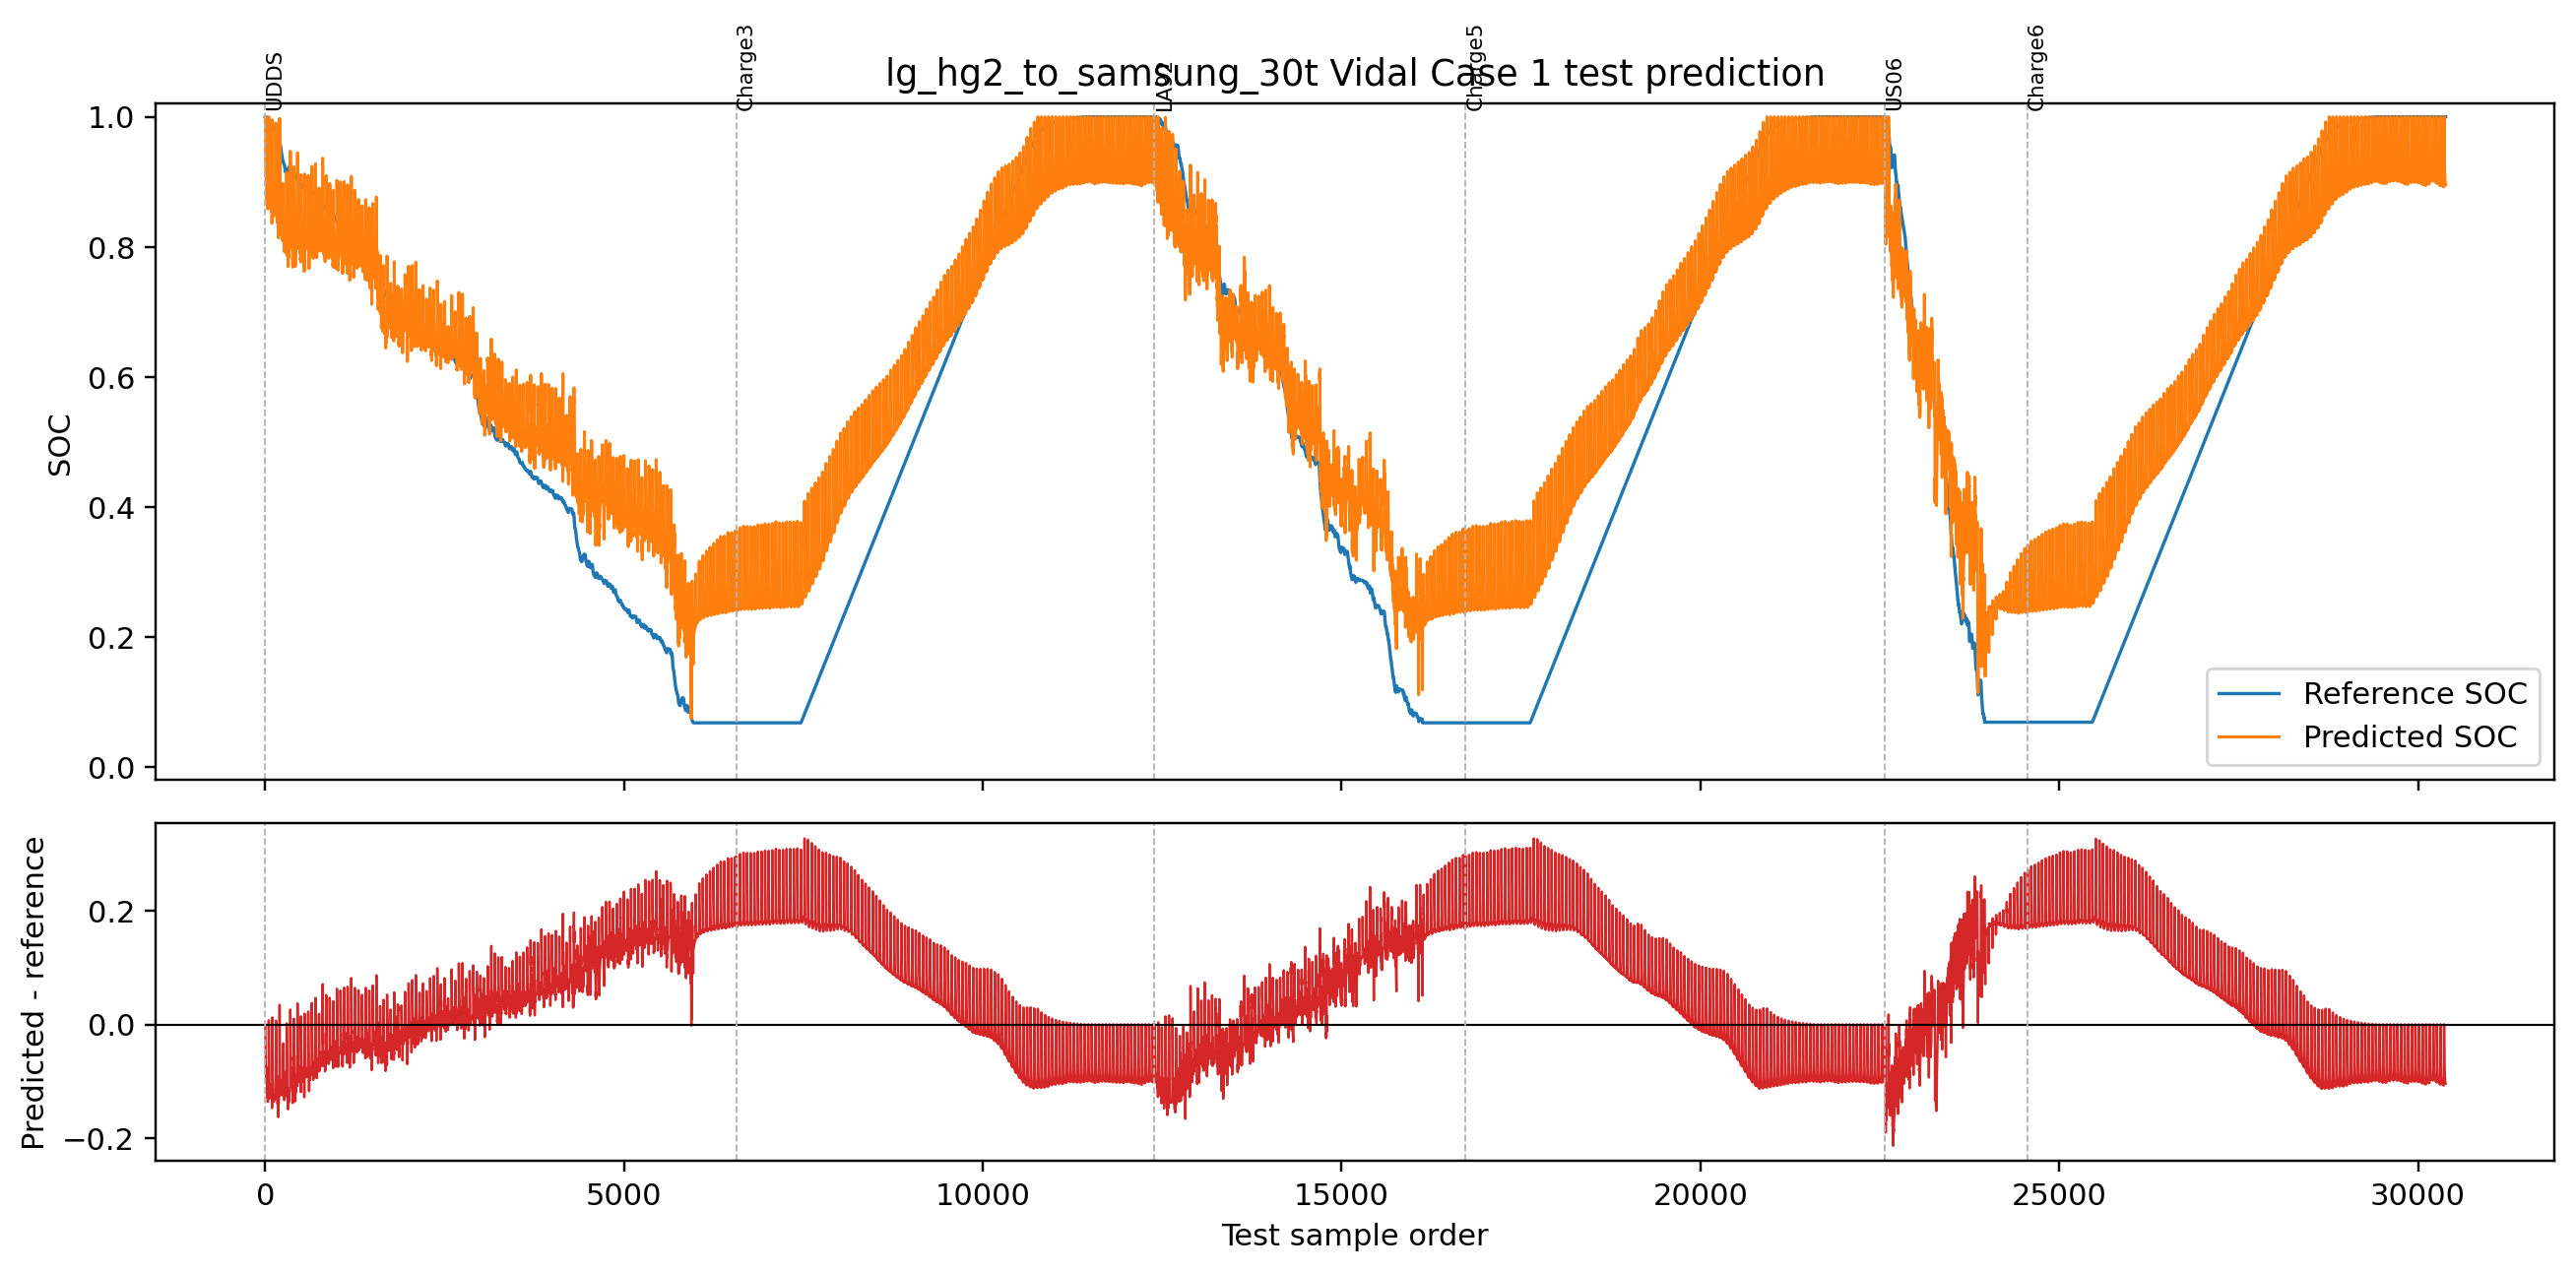

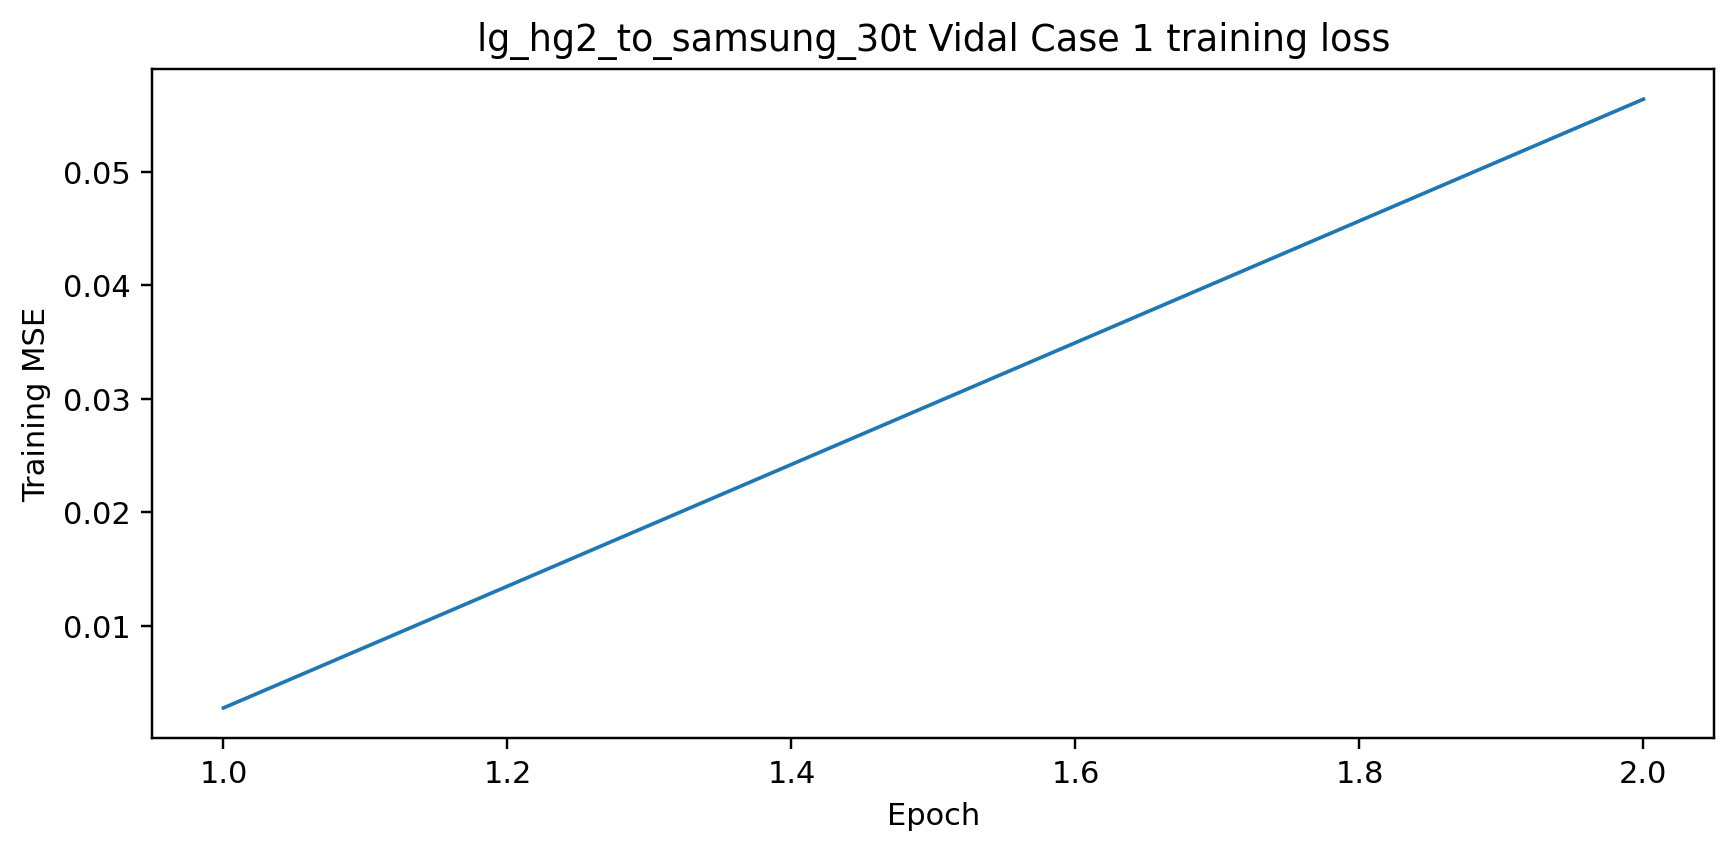

In [9]:
pair_root = CASE2_OUTPUT_ROOT / '_smoke' / f'source_{SOURCE}__target_{TARGET}' / 'seed_42'
latest = sorted(pair_root.iterdir(), key=lambda p: p.stat().st_mtime)[-1]
print('Latest Case 2 smoke:', latest)
metadata = json.loads((latest / 'run_metadata.json').read_text())
metrics = json.loads((latest / 'metrics.json').read_text())
comparison = json.loads((latest / 'comparison_to_case1.json').read_text())
print('source checkpoint:', metadata['source_checkpoint']['source_checkpoint_path'])
print('checkpoint sha256:', metadata['source_checkpoint']['source_checkpoint_sha256'])
print('initial_target_mse_before_training:', metadata['initial_target_mse_before_training'])
print('final_target_train_mse:', metadata['final_target_train_mse'])
print('metrics:', metrics)
print('comparison:', comparison)
display(pd.read_csv(latest / 'scaler.json') if False else pd.DataFrame([json.loads((latest / 'scaler.json').read_text())]))
for fig in sorted((latest / 'figures').glob('*.png')):
    display(Image(filename=str(fig)))

## Formal commands

Single formal pair example:

```bash
python scripts/run_vidal_case2.py   --source lg_hg2   --target samsung_30t   --config configs/experiments/vidal_case2.yaml   --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2   --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2   --case1-output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1   --source-checkpoint /path/to/lg_hg2/seed_42/<run_id>/checkpoints/epoch_515.pt   --run-mode formal
```

Six-direction run example:

```bash
python scripts/run_vidal_case2.py   --all-pairs   --config configs/experiments/vidal_case2.yaml   --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2   --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2   --case1-output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1   --source-checkpoint-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1   --run-mode formal
```

The notebook does not launch these formal commands automatically.

In [13]:
from pathlib import Path
import yaml

config_path = Path(
    "/content/battery-soc-transfer-benchmark/"
    "configs/experiments/vidal_case2_smoke.yaml"
)

config = yaml.safe_load(config_path.read_text())

config["epochs"] = 5
config["batch_size"] = 512
config["max_train_windows"] = None
config["development_only"] = True
config["verify_hashes"] = False
config["resample_hz"] = 1.0

config_path.write_text(
    yaml.safe_dump(config, sort_keys=False),
    encoding="utf-8",
)

print(config_path.read_text())

run_mode: smoke
random_seed: 42
seq_len: 50
stride: 50
epochs: 5
batch_size: 512
learning_rate: 0.01
scheduler_step_size: 100
scheduler_gamma: 0.5
shuffle: true
num_workers: 0
max_train_windows: null
allowed_statuses:
- PASS
- WARNING
development_only: true
verify_hashes: false
resample_hz: 1.0



In [14]:
%cd /content/battery-soc-transfer-benchmark

/content/battery-soc-transfer-benchmark


In [15]:
!python scripts/run_vidal_case2.py \
  --source lg_hg2 \
  --target samsung_30t \
  --config configs/experiments/vidal_case2_smoke.yaml \
  --input-root /content/drive/MyDrive/battery_soc_benchmark/data/labelled/vidal_sequence_v2 \
  --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2 \
  --case1-output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1 \
  --source-checkpoint /content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/lg_hg2/seed_42/20260716_090927_c4728bba/checkpoints/epoch_515.pt \
  --run-mode smoke \
  --device auto

[
  {
    "run_dir": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case2/_smoke/source_lg_hg2__target_samsung_30t/seed_42/20260716_110357_db5adbe5_dirty",
    "metrics": {
      "mae_fraction": 0.05358179521144421,
      "mae_percent": 5.358179521144421,
      "rmse_fraction": 0.06813351675598424,
      "rmse_percent": 6.813351675598424,
      "max_error_fraction": 0.2590053677558899,
      "max_error_percent": 25.90053677558899,
      "bias_fraction": 0.04241759088122098,
      "bias_percent": 4.241759088122098,
      "r2": 0.959516556059457
    },
    "comparison_to_case1": {
      "baseline_available": true,
      "target_case1_run_path": "/content/drive/MyDrive/battery_soc_benchmark/outputs/vidal_case1/samsung_30t/seed_42/20260716_091258_c4728bba",
      "case1_target_rmse_percent": 2.8078941683251415,
      "case2_rmse_percent": 6.813351675598424,
      "rmse_delta_percent_points": 4.005457507273283,
      "rmse_relative_change_percent": 142.64987450230242,
      "ca